# Analisis Big Data - Bab 1: Statistics and Probability
## Listing 1-1 s.d. 1-14 (studi kasus Seattle Cycle Share)

Kode pada buku ditulis dalam Python 2. Di sini seluruh listing disesuaikan ke Python 3 tanpa mengubah tujuan analisisnya. Letakkan `trip.csv` satu folder dengan notebook ini.

Penyesuaian utama:
- `print x` menjadi `print(x)`.
- `.ix` (sudah dihapus dari pandas) diganti `.iloc`/`.loc`, dan rentang waktu dihitung dari kolom bertipe datetime, bukan urutan string.
- Impor yang tidak terpakai (`random`, `statistics`, `datetime`) dibuang.

### Listing 1-1. Importing Packages Required for This Chapter

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

### Listing 1-2. Reading the Data into Memory

In [2]:
DATA_PATH = 'trip.csv'
TIME_FORMAT = '%m/%d/%Y %H:%M'

data = pd.read_csv(DATA_PATH)

### Listing 1-3. Printing Size of the Dataset and Printing First Few Rows

In [3]:
print(len(data))
data.head()

236065


,trip_id,starttime,stoptime,bikeid,tripduration,from_station_name,to_station_name,from_station_id,to_station_id,usertype,gender,birthyear
0,431,10/13/2014 10:31,10/13/2014 10:48,SEA00298,985.935,2nd Ave & Spring St,Occidental Park / Occidental Ave S & S Washing...,CBD-06,PS-04,Member,Male,1960.0
1,432,10/13/2014 10:32,10/13/2014 10:48,SEA00195,926.375,2nd Ave & Spring St,Occidental Park / Occidental Ave S & S Washing...,CBD-06,PS-04,Member,Male,1970.0
2,433,10/13/2014 10:33,10/13/2014 10:48,SEA00486,883.831,2nd Ave & Spring St,Occidental Park / Occidental Ave S & S Washing...,CBD-06,PS-04,Member,Female,1988.0
3,434,10/13/2014 10:34,10/13/2014 10:48,SEA00333,865.937,2nd Ave & Spring St,Occidental Park / Occidental Ave S & S Washing...,CBD-06,PS-04,Member,Female,1977.0
4,435,10/13/2014 10:34,10/13/2014 10:49,SEA00202,923.923,2nd Ave & Spring St,Occidental Park / Occidental Ave S & S Washing...,CBD-06,PS-04,Member,Male,1971.0


### Listing 1-4. Determining the Time Range of the Dataset

In [4]:
start_times = pd.to_datetime(data['starttime'], format=TIME_FORMAT)
stop_times = pd.to_datetime(data['stoptime'], format=TIME_FORMAT)

print(f'Date range of dataset: {start_times.min():%m/%d/%Y %H:%M} - '
      f'{stop_times.max():%m/%d/%Y %H:%M}')

Date range of dataset: 10/13/2014 10:31 - 09/01/2016 00:20


### Listing 1-5. Plotting the Distribution of User Types

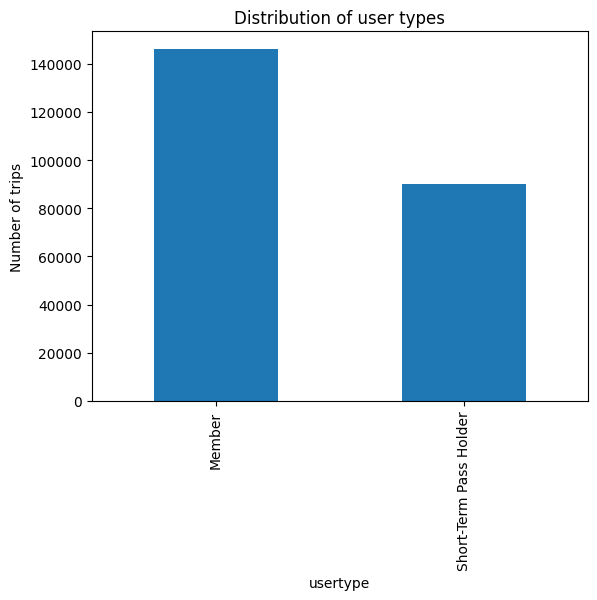

In [5]:
groupby_user = data.groupby('usertype').size()
groupby_user.plot.bar(title='Distribution of user types', ylabel='Number of trips')
plt.show()

### Listing 1-6. Plotting the Distribution of Gender

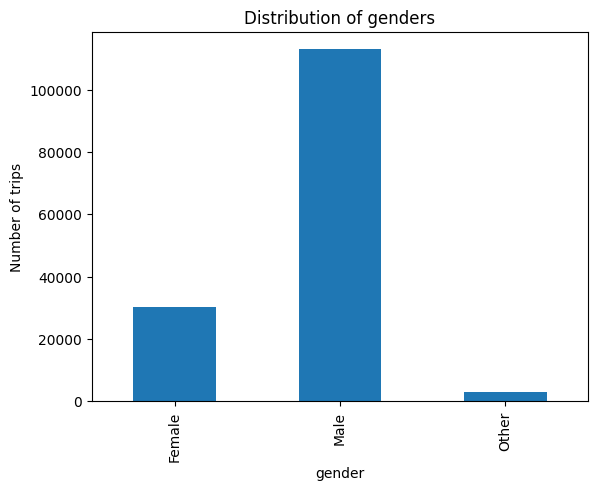

In [6]:
groupby_gender = data.groupby('gender').size()
groupby_gender.plot.bar(title='Distribution of genders', ylabel='Number of trips')
plt.show()

### Listing 1-7. Plotting the Distribution of Birth Years

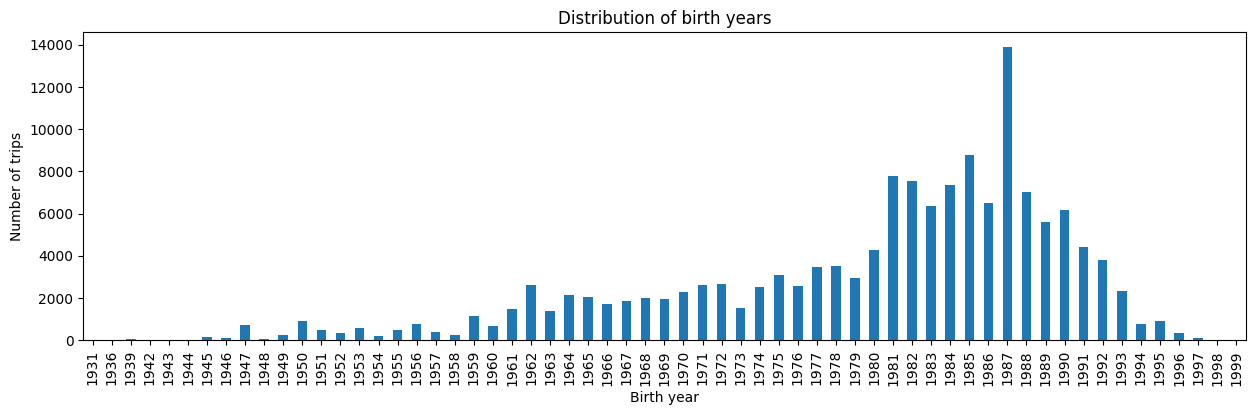

In [7]:
groupby_birthyear = data['birthyear'].dropna().astype(int).value_counts().sort_index()
groupby_birthyear.plot.bar(title='Distribution of birth years', figsize=(15, 4),
                           xlabel='Birth year', ylabel='Number of trips')
plt.show()

### Listing 1-8. Plotting the Frequency of Member Types for Millennials

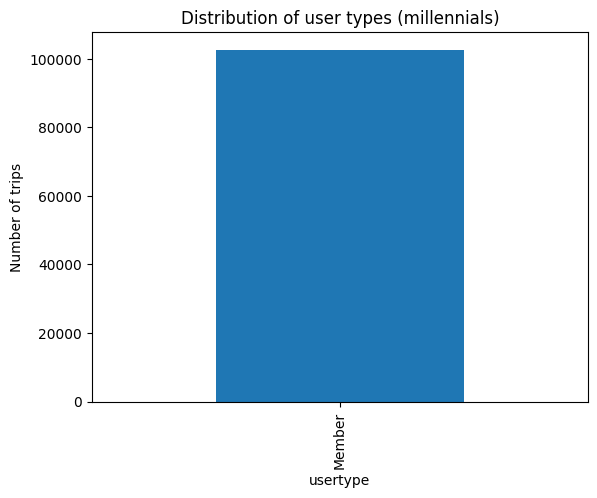

In [8]:
data_mil = data[data['birthyear'].between(1977, 1994)]
groupby_mil = data_mil.groupby('usertype').size()
groupby_mil.plot.bar(title='Distribution of user types (millennials)',
                     ylabel='Number of trips')
plt.show()

### Listing 1-9. Plotting the Distribution of Birth Years by Gender Type

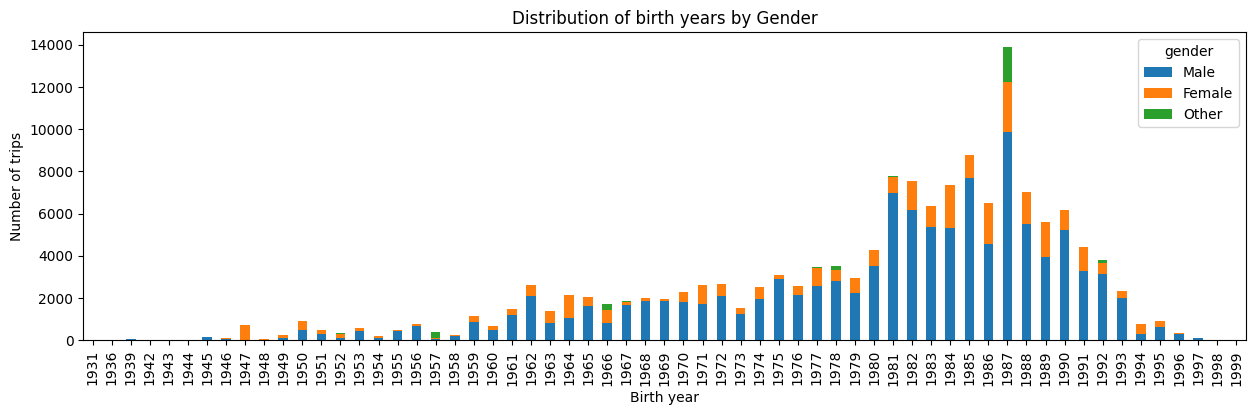

In [9]:
groupby_birthyear_gender = (
    data.groupby(['birthyear', 'gender'])
    .size()
    .unstack('gender', fill_value=0)
)
groupby_birthyear_gender.index = groupby_birthyear_gender.index.astype(int)
groupby_birthyear_gender[['Male', 'Female', 'Other']].plot.bar(
    title='Distribution of birth years by Gender', stacked=True, figsize=(15, 4),
    xlabel='Birth year', ylabel='Number of trips')
plt.show()

### Listing 1-10. Plotting the Distribution of Birth Years by User Types

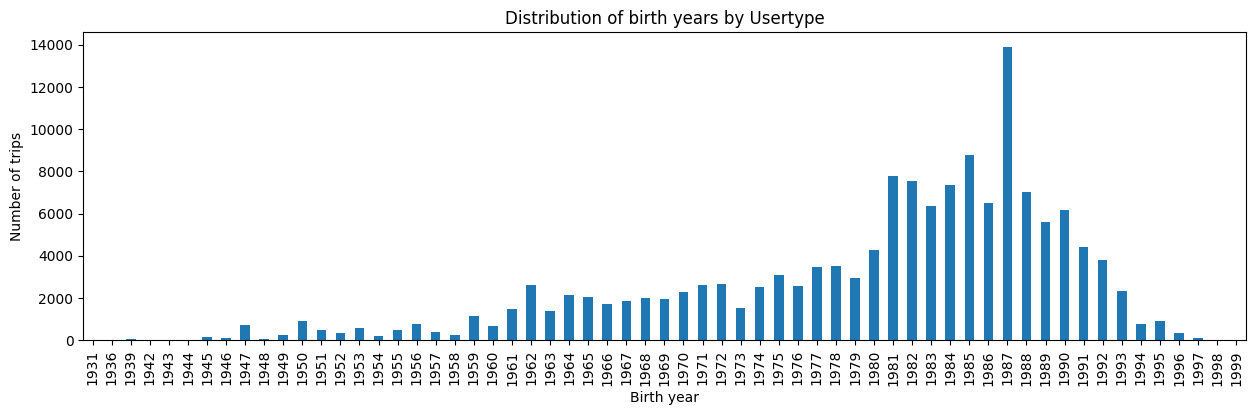

In [10]:
groupby_birthyear_user = (
    data.groupby(['birthyear', 'usertype'])
    .size()
    .unstack('usertype', fill_value=0)
)
groupby_birthyear_user.index = groupby_birthyear_user.index.astype(int)
groupby_birthyear_user['Member'].plot.bar(
    title='Distribution of birth years by Usertype', stacked=True, figsize=(15, 4),
    xlabel='Birth year', ylabel='Number of trips')
plt.show()

### Listing 1-11. Validation If We Don't Have Birth Year Available for Short-Term Pass Holders

In [11]:
is_short_term = data['usertype'] == 'Short-Term Pass Holder'
print(data.loc[is_short_term, 'birthyear'].isnull().all())

True


### Listing 1-12. Validation If We Don't Have Gender Available for Short-Term Pass Holders

In [12]:
print(data.loc[is_short_term, 'gender'].isnull().all())

True


### Listing 1-13. Converting String to datetime, and Deriving New Features

In [13]:
start_time = pd.to_datetime(data['starttime'], format=TIME_FORMAT)

data['starttime_mod'] = start_time
data['starttime_date'] = start_time.dt.date
data['starttime_year'] = start_time.dt.year
data['starttime_month'] = start_time.dt.month
data['starttime_day'] = start_time.dt.day
data['starttime_hour'] = start_time.dt.hour

data[['starttime', 'starttime_mod', 'starttime_date', 'starttime_year',
      'starttime_month', 'starttime_day', 'starttime_hour']].head()

,starttime,starttime_mod,starttime_date,starttime_year,starttime_month,starttime_day,starttime_hour
0,10/13/2014 10:31,2014-10-13 10:31:00,2014-10-13,2014,10,13,10
1,10/13/2014 10:32,2014-10-13 10:32:00,2014-10-13,2014,10,13,10
2,10/13/2014 10:33,2014-10-13 10:33:00,2014-10-13,2014,10,13,10
3,10/13/2014 10:34,2014-10-13 10:34:00,2014-10-13,2014,10,13,10
4,10/13/2014 10:34,2014-10-13 10:34:00,2014-10-13,2014,10,13,10


### Listing 1-14. Plotting the Distribution of Trip Duration over Daily Time

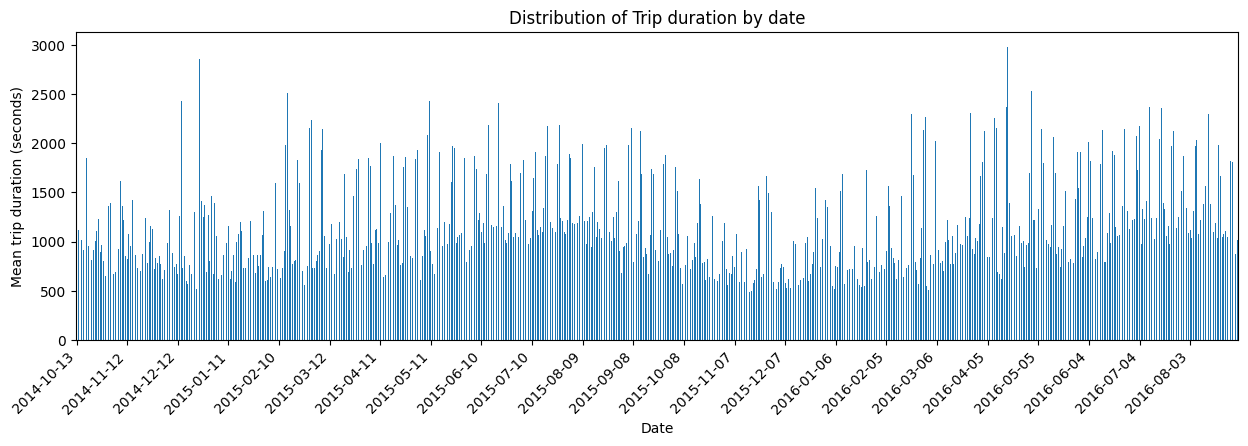

In [14]:
daily_duration = data.groupby('starttime_date')['tripduration'].mean()

ax = daily_duration.plot.bar(title='Distribution of Trip duration by date', figsize=(15, 4),
                             xlabel='Date', ylabel='Mean trip duration (seconds)')
step = 30
ax.set_xticks(range(0, len(daily_duration), step))
ax.set_xticklabels(daily_duration.index[::step], rotation=45, ha='right')
plt.show()